#Install Packages

In [1]:
!pip install pyvirtualdisplay

In [2]:
import numpy as np
import gymnasium as gym
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import os
from pathlib import Path
from torch.distributions import Categorical
from google.colab import drive
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
from IPython import display as ipythondisplay
from pyvirtualdisplay import Display
from gym.wrappers.record_video import RecordVideo
import base64
import random

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
checkpoint = None
initepochs = 0

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#Policy Network

In [9]:
class PolicyNetwork(nn.Module):
  def __init__(self, s_size, a_size, hidden1, hidden2):
    super(PolicyNetwork, self).__init__()
    self.fc1 = nn.Linear(s_size, hidden1)
    self.fc2 = nn.Linear(hidden1, hidden2)
    self.fc3 = nn.Linear(hidden2, a_size)

    torch.nn.init.xavier_uniform_(self.fc1.weight)
    torch.nn.init.xavier_uniform_(self.fc2.weight)
    torch.nn.init.xavier_uniform_(self.fc3.weight)
    torch.nn.init.zeros_(self.fc1.bias)
    torch.nn.init.zeros_(self.fc2.bias)
    torch.nn.init.zeros_(self.fc3.bias)

  def forward(self, state):
    """
    Perform a forward pass
    Params
    ======
        state: the input state
    """
    ### your code ###
    x = F.relu(self.fc1(state))
    x = F.relu(self.fc2(x))
    x = self.fc3(x)
    return x

  def select_greedy_action(self, state):
    """
    Perform a forward pass, and selects the greedy action
    This is useful for evaluation rollouts

    Params
    ======
        state: the input state
    """
    ### your code ###‌
    state = torch.from_numpy(state).float().unsqueeze(0).to(device)
    x = self.forward(state)
    return np.argmax(torch.tensor(x).cpu()).item()

#CEM Algorithm

In [13]:
class CEMAgent():
  def __init__(self, seedrange, state_size, action_size):
    self.state_size = state_size
    self.action_size = action_size

    self.seedrange = seedrange

    self.seed = random.randint(self.seedrange[0], self.seedrange[1])

    torch.manual_seed(self.seed)
    np.random.seed(self.seed)
    random.seed(self.seed)

    #Initialized policy network
    self.pnetwork = PolicyNetwork(self.state_size, self.action_size, 32, 32).to(device)

  #Save checkpoint for epoch, pnetwork, and result
  def savecheckpoint(self, epoch, bestpnetwork, filename):
    torch.save({
        'epoch': epoch,
        'pnetwork': bestpnetwork.state_dict(),
        'seed': self.seed,
        'results': list(self.result),
        }, filename)

  #Load checkpoint to model
  def loadcheckpoint(self, checkpoint):
    self.initepoch = checkpoint['epoch']
    self.pnetwork.load_state_dict(torch.load(checkpoint['pnetwork']))
    self.results = np.array(checkpoint['results'])

  #Provide one hot encoding for state
  def onehotstate(self, state):
    #Extract each component from state tuple
    playersum, dealercard, usableace = state
    #Player vector
    playervector = np.zeros(32)
    #Dealer vector
    dealervector = np.zeros(11)
    #Usable ace vector
    usableacevector = np.zeros(2)

    #Set vectors to indicate state values
    playervector[playersum] = 1
    dealervector[dealercard - 1] = 1
    usableacevector[usableace] = 1

    #Represent state as concatenation of np vectors
    return np.concatenate([playervector, dealervector, usableacevector])

  #Get results
  def getresults(self):
    return self.results

  def evaluate(self, env, n_rollouts):
    """
    Returns the mean score obtained by executing a deterministic policy for a fixed number of rollouts.

    Params
    ======
        env: the environment
        n_rollouts (int): the number of rollouts to be performed
    """

    self.seed = random.randint(self.seedrange[0], self.seedrange[1])

    torch.manual_seed(self.seed)
    np.random.seed(self.seed)
    random.seed(self.seed)

    rewards = 0
    loss = 0
    bust = 0
    for _ in range(n_rollouts):
      state, info = env.reset()
      #Extract each component from state tuple
      playersum, dealercard, usableace = state
      state = self.onehotstate(state) #Set state to one hot encoding np vector

      terminal = False
      while not terminal:
        action = self.pnetwork.select_greedy_action(state)
        state, reward, terminal, trunc, _ = env.step(action)
        state = self.onehotstate(state) #Set state to one hot encoding np vector

        if (reward == 1):
          rewards += reward

        elif (reward == -1):
          loss += 1

          if (playersum > 21):
            bust += 1

    return rewards / n_rollouts, bust / loss

  #Gets N weights from μ, σ
  def getweights(self, μ, σ):
    paramdim = 0 #Total dimensions of weights

    #Iterate through pnetwork parameters to find weight parameters
    for name, param in self.pnetwork.named_parameters():
      paramdim += param.data.numel()

    self.weights = [μ + σ * (np.random.randn(paramdim)) for i in range(self.n)]

  #Get policy vector from weights
  def weight2policy(self):
    policies = []

    #Iterate through each weight
    for weight in self.weights:
      weightpolicy = PolicyNetwork(self.state_size, self.action_size, 32, 32).to(device)

      idx = 0

      #Iterate through policy network parameters to find weight parameters
      for name, param in weightpolicy.named_parameters():
        #Get flattened shape of parameter
        paramdims = param.numel()
        #Get section of weight
        paramweight = weight[idx:idx + paramdims]
        #Convert section to tensor
        tensorparamweight = torch.tensor(paramweight).to(device)
        #Reshape weight tensor
        tensorparamweight = tensorparamweight.reshape(param.data.shape)

        #Set weight data to copy tensor weight
        param.data.copy_(tensorparamweight)

        #Update idx
        idx += paramdims

      #Add new policy to policies list
      policies.append(weightpolicy)

    return policies

  #Update pnetwork
  def updatepnetwork(self, μ):
    #Iterate through policy network parameters to find weight parameters
    for name, param in self.pnetwork.named_parameters():
      #Get flattened shape of weight
      paramdims = param.numel()
      #Get new weights using μ
      newweights = [μ for i in range(paramdims)]
      #Convert newweights to tensor
      tensornewweights = torch.tensor(newweights).to(device)
      #Reshape weight tensor
      tensornewweights = tensornewweights.reshape(param.data.shape)

      #Set weight data to copy tensor weight
      param.data.copy_(tensornewweights)

  #Acquires trajectory rewards
  def collecttrajectory(self, policy):

    t = 0 #Number of steps in trajectory
    state, info = env.reset() #Reset state for new trajectory
    state = self.onehotstate(state) #Set state to one hot encoding np vector

    while(True):
      action = policy.select_greedy_action(state) #Select action with policy
      new_state, reward, terminal, trunc, _ = env.step(action) #Collect experience

      self.trewards += reward #Add reward to cumulative reward for trajectory
      state = new_state #Set state to new state
      state = self.onehotstate(state) #Set state to one hot encoding np vector

      t += 1
      self.totalsteps += 1
      #Stop when we hit terminal state or max steps (choose 11 where in worst case we use 11 cards to reach 21 or higher)
      if (terminal or t == 11):
        break

  #Training function
  def train(self, env, epochs, n, k, checkpoint, goalreward):
    self.epochs = epochs
    self.initepochs = 0
    self.n = n
    #Let k be the proportion (k/100) rather than k%
    self.k = k

    #For checkpoint is used
    if (checkpoint != None):
      self.loadcheckpoint(checkpoint)

    #Bookkeeping
    self.totalsteps = 0
    self.evalscores = []
    self.trainscores = []
    self.bustrate = []
    self.result = np.empty((self.epochs, 4))
    self.result[:] = np.nan

    #Initialize μ and σ
    μ, σ = 0.0, 1.0

    #Best so far
    bestevalscore = 0.0
    bestpnetwork = self.pnetwork

    for epoch in range(self.initepochs, self.epochs):

      #Update seed with random value
      if ((epoch + 1) % 2 == 0):
        self.seed = random.randint(self.seedrange[0], self.seedrange[1])
        torch.manual_seed(self.seed)
        np.random.seed(self.seed)
        random.seed(self.seed)

      self.weights = [] #Weights for iteration. Clear out for each new iteration
      self.rewards = [] #Rewards for iteration. Clear out for each new iteration

      #Sample a population of n weights θi ~ N(μ, σ^2I)
      self.getweights(μ, σ)
      #Get polices from sampled weights
      policies = self.weight2policy()

      #For each θi, collect a rollout Tj and get the return Gj = R(Tj)
      for j in range(len(policies)):
        self.trewards = 0 #Cumulative reward for each rollout. Clear out for each new trajectory
        self.collecttrajectory(policies[j]) #Collect trajectory using θi policy
        self.rewards.append(self.trewards) #Append trajectory reward to iteration rewards

      #Select the top k% of θi
      topk = np.argsort(np.array(self.rewards))[: int(n * k)] #Get the top k θ indices sorted by cumulative rewards
      topksamples = [self.weights[topk[k]] for k in range(len(topk))] #Get top k θ from indices

      #Estimate new μ and σ using the selected samples
      μ, σ = np.array(topksamples).mean(), np.array(topksamples).std()

      #Update policy with new mean and std
      self.updatepnetwork(μ)

      #Get training reward per iteration
      trainrewards = np.array(self.rewards)
      trainscore = trainrewards.mean()
      self.trainscores.append(trainscore)

      #Get eval score and bust rate for iteration
      evalscore, bustrate = self.evaluate(env, 2000)
      self.evalscores.append(evalscore)
      self.bustrate.append(bustrate)

      #Get mean train reward
      meantrains = np.mean(self.trainscores[-100:])

      #Get mean evaluation reward
      meanevals = np.mean(self.evalscores[-100:])

      #Update best eval so far
      if (evalscore > bestevalscore):
        bestevalscore = evalscore
        bestpnetwork = self.pnetwork

      #Update results
      self.result[epoch] = self.totalsteps, meanevals, meantrains, self.bustrate[epoch]

      #Save model per epoch
      self.savecheckpoint(epoch, bestpnetwork, 'CEM.pt')

      #Print epoch steps and rewards
      print(f"Epoch {epoch}, Total steps: {self.totalsteps}, Training Reward: {meantrains}, Eval Reward: {meanevals}")

      if (meanevals >= goalreward):
        print(f"Solved in {epoch} epochs and {self.totalsteps} steps with average eval reward of {meanevals}")
        break

    return np.array(self.result)


#Train CEM

In [5]:
#For reseting the checkpoint and epochs
initepochs = 0
checkpoint = None

In [14]:
env = gym.make('Blackjack-v1', natural=False, sab=False)

n = 100
k = 0.2
epochs = initepochs + 500
goalreward = 0.42
seedrange = [0, int(1e6)]
observationsize = 32 + 11 + 2

cemagent = CEMAgent(seedrange, observationsize, env.action_space.n)
cemresults = cemagent.train(env, epochs, n, k, checkpoint, goalreward)

/tmp/ipython-input-4004054401.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return np.argmax(torch.tensor(x).cpu()).item()
/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:48: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return conv.wrap(result, to_scalar=False)


Epoch 0, Total steps: 139, Training Reward: -0.42, Eval Reward: 0.392
Epoch 1, Total steps: 285, Training Reward: -0.52, Eval Reward: 0.39925
Epoch 2, Total steps: 440, Training Reward: -0.5733333333333334, Eval Reward: 0.3985
Epoch 3, Total steps: 585, Training Reward: -0.5625, Eval Reward: 0.395
Epoch 4, Total steps: 748, Training Reward: -0.58, Eval Reward: 0.39080000000000004
Epoch 5, Total steps: 893, Training Reward: -0.5383333333333333, Eval Reward: 0.3875833333333334
Epoch 6, Total steps: 1035, Training Reward: -0.5385714285714286, Eval Reward: 0.3855
Epoch 7, Total steps: 1168, Training Reward: -0.52, Eval Reward: 0.386375
Epoch 8, Total steps: 1315, Training Reward: -0.5211111111111112, Eval Reward: 0.3859444444444444
Epoch 9, Total steps: 1465, Training Reward: -0.5090000000000001, Eval Reward: 0.38775
Epoch 10, Total steps: 1597, Training Reward: -0.5136363636363637, Eval Reward: 0.3877272727272727
Epoch 11, Total steps: 1736, Training Reward: -0.5016666666666667, Eval Rewa

In [ ]:
#Use this to get results if we stop in the middle of training
cemresults = cemagent.getresults()

#Save CEM

In [15]:
from google.colab import files
files.download('CEM.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#Plot CEM Results

Text(0.5, 1.0, 'Bust Rate')

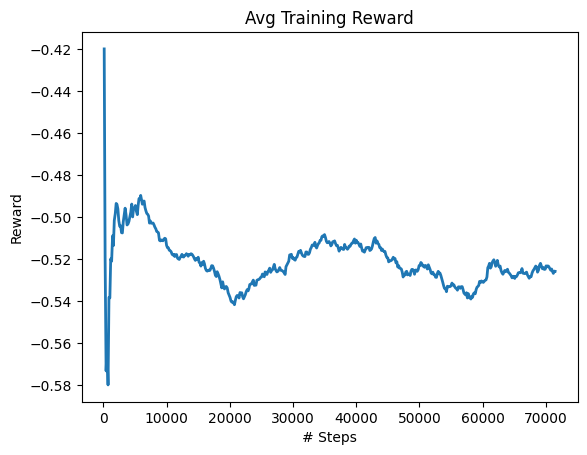

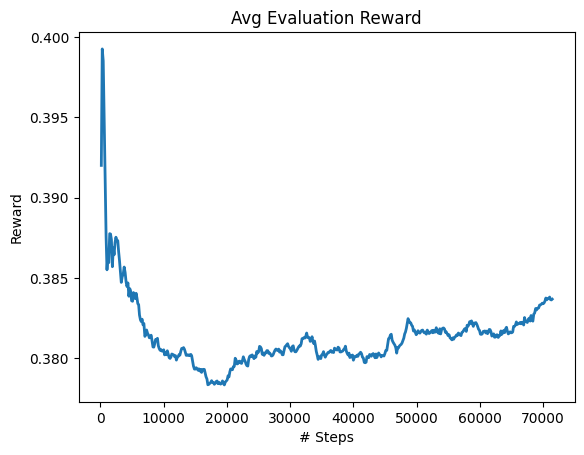

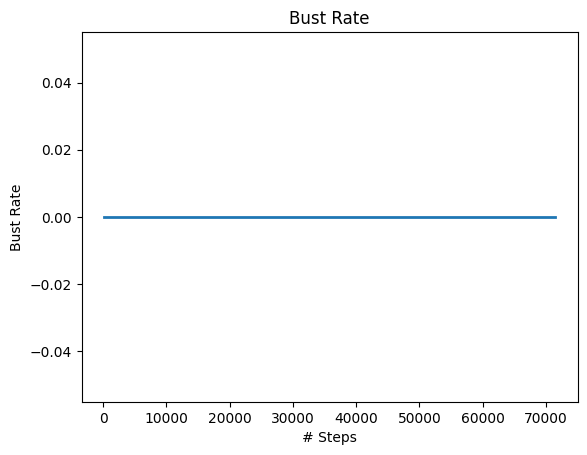

In [17]:
cemsteps, cemeval, cemtrain, cembustrate = cemresults.T

fig1 = plt.figure()
ax1 = fig1.add_subplot(111)
plt.plot(cemsteps, cemtrain, linewidth=2)
plt.ylabel('Reward')
plt.xlabel('# Steps')
ax1.set_title('Avg Training Reward')

fig2 = plt.figure()
ax2 = fig2.add_subplot(111)
plt.plot(cemsteps, cemeval, linewidth=2)
plt.ylabel('Reward')
plt.xlabel('# Steps')
ax2.set_title('Avg Evaluation Reward')

fig3 = plt.figure()
ax3 = fig3.add_subplot(111)
plt.plot(cemsteps, cembustrate, linewidth=2)
plt.ylabel('Bust Rate')
plt.xlabel('# Steps')
ax3.set_title('Bust Rate')

#Reload CEM checkpoint

In [ ]:
if (os.path.exists('CEM.pt')):
  checkpoint = torch.load('CEM.pt', weights_only=True)
  initepochs = checkpoint['epochs']
else:
  print(f"Train CEM model first")

#Visuals for Blackjack

In [ ]:
display = Display(visible=0, size=(600, 400))
display.start()

def show_video(path):
    html = []
    for mp4 in Path(path).glob("*.mp4"):
        video_b64 = base64.b64encode(mp4.read_bytes())
        html.append('''<video alt="{}" autoplay
                      controls style="height: 400px;">
                      <source src="data:video/mp4;base64,{}" type="video/mp4" />
                 </video>'''.format(mp4, video_b64.decode('ascii')))
    ipythondisplay.display(ipythondisplay.HTML(data="<br>".join(html)))

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
env = gym.make('Blackjack-v1', natural=False, sab=False, render_mode="rgb_array")
env = RecordVideo(env, './video', episode_trigger = lambda episode_number: True)

state, _ = env.reset()
state = cemagent.onehotstate(state) #Set state to one hot encoding np vector

terminal = False
while not terminal:
  action = cemagent.pnetwork.select_greedy_action(state)#env.action_space.sample()
  state, reward, terminal, _ = env.step(action)
  state = cemagent.onehotstate(state) #Set state to one hot encoding np vector
env.close()
show_video('./video')

/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/record_video.py:78: UserWarning: WARN: Overwriting existing videos at /content/video folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/tmp/ipython-input-2037032977.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone(